[transformers] Model config: pad_token_id must be `None` or an integer within the vocabulary (between 0 and 2047), got 2048. This may result in unexpected behavior.
[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 2047), got 2048. This may result in unexpected behavior.


Loading weights:   0%|          | 0/611 [00:00<?, ?it/s]

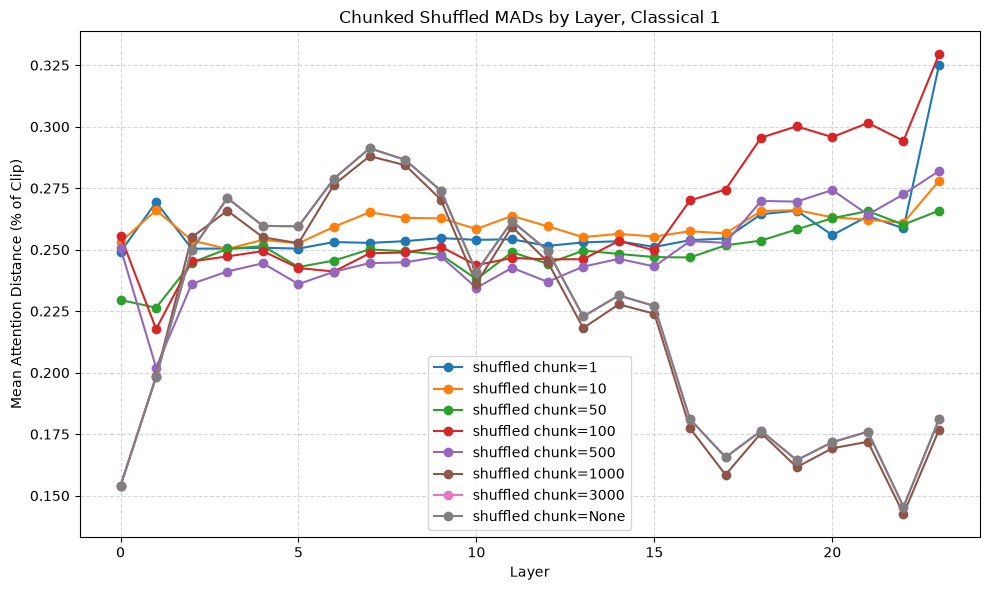

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import utils

audio_paths = [
    # "../music-clips/classical_1.wav",
    "../music-clips/classical_2.wav",
    # "../music-clips/classical_6.wav"
    # "../music-clips/electronic_1.wav",
    # "../music-clips/electronic_3.wav",
    # "../music-clips/electronic_14.wav",
]

model, processor = utils.load_music_gen_model()
wfs = utils.load_process_bulk_audio(audio_paths, sr=32000)
inputs_dict = utils.process_bulk_music_gen(wfs, processor=processor)

chunk_sizes = [1, 10, 50, 100, 500, 1000, 3000, None]
mad_dicts = []
labels = []
for chunk_size in chunk_sizes:
    attentions = utils.extract_attentions(model, inputs_dict, chunk_size=chunk_size)
    mad_dicts.append(utils.compute_mad_dict(attentions))
    labels.append(f"shuffled chunk={chunk_size}")



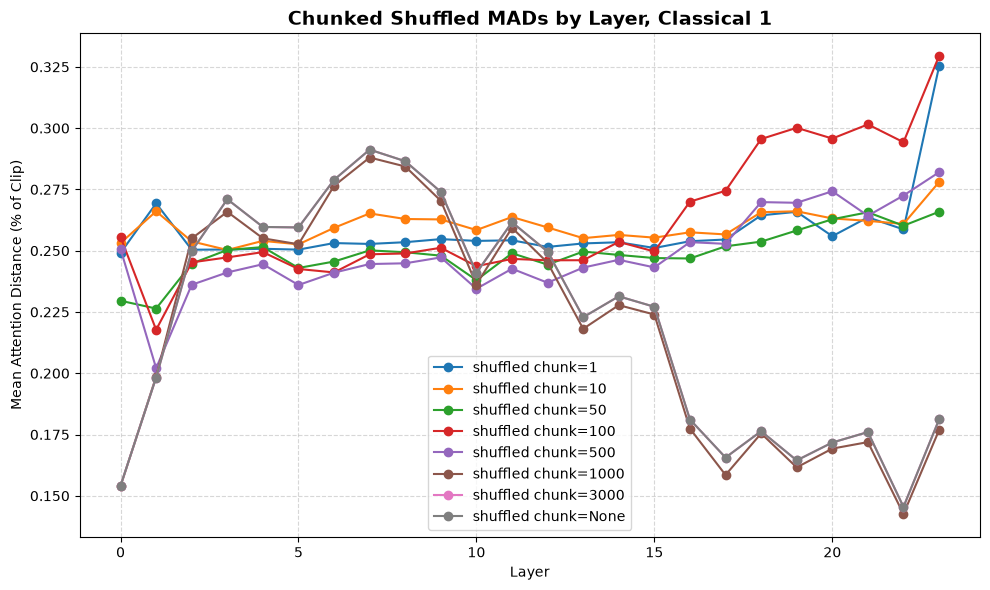

In [2]:
def plot_chunked_mads(mad_dicts, labels):
    plt.figure(figsize=(10, 6))
    for label, mad_dict in zip(labels, mad_dicts):
        layer_means = []
        for path, mads in mad_dict.items():
            layer_means.append(np.mean(mads, axis=1))
        if not layer_means:
            continue
        mean_per_layer = np.mean(np.stack(layer_means, axis=0), axis=0)
        plt.plot(
            range(len(mean_per_layer)),
            mean_per_layer,
            marker="o",
            linewidth=1.5,
            label=label
        )

    plt.title("Chunked Shuffled MADs by Layer, Classical 1",fontsize=14, fontweight='bold')
    plt.xlabel("Layer")
    plt.ylabel("Mean Attention Distance (% of Clip)")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_chunked_mads(mad_dicts, labels)
